## ***Netflix Movies and TV Shows Data Analysis Project***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn  as sns

In [2]:
netflix=pd.read_csv('netflix_titles.csv')

In [39]:
print(netflix.shape)

(8807, 11)


In [38]:
netflix.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   show_id         8807 non-null   str           
 1   content_type    8807 non-null   str           
 2   title           8807 non-null   str           
 3   director        8807 non-null   str           
 4   cast            8807 non-null   str           
 5   country         8807 non-null   str           
 6   date_added      8709 non-null   datetime64[us]
 7   release_year    8807 non-null   int64         
 8   content_rating  8807 non-null   str           
 9   duration        8807 non-null   str           
 10  genre           8807 non-null   str           
dtypes: datetime64[us](1), int64(1), str(9)
memory usage: 757.0 KB


In [40]:
netflix.head()

,show_id,content_type,title,director,cast,country,date_added,release_year,content_rating,duration,genre
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries"
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV"
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ..."


In [37]:
netflix['release_year'].min()  # 1925
netflix['release_year'].max()

np.int64(2021)

## Data Cleaning

###  1.Renaming columns


In [5]:
rename = {'type':'content_type',
          'rating':'content_rating',
          'listed_in':'genre'
}

netflix.rename(columns=rename,inplace=True)

In [6]:
netflix.head()

,show_id,content_type,title,director,cast,country,date_added,release_year,content_rating,duration,genre,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


### 2.Remove Duplicates

In [7]:
netflix.duplicated().sum()

np.int64(0)

### 3.Changing the Data Present in a Particular Column

In [9]:
netflix['content_type'].unique()

<StringArray>
['Movie', 'TV Show']
Length: 2, dtype: str

In [10]:
netflix['content_rating'].unique()

<StringArray>
[   'PG-13',    'TV-MA',       'PG',    'TV-14',    'TV-PG',     'TV-Y',
    'TV-Y7',        'R',     'TV-G',        'G',    'NC-17',   '74 min',
   '84 min',   '66 min',       'NR',        nan, 'TV-Y7-FV',       'UR']
Length: 18, dtype: str

In [11]:
netflix[netflix['content_rating'].str.contains('min', na=False)]

,show_id,content_type,title,director,cast,country,date_added,release_year,content_rating,duration,genre,description
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,"April 4, 2017",2017,74 min,NaN,Movies,"Louis C.K. muses on religion, eternal love, gi..."
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,"September 16, 2016",2010,84 min,NaN,Movies,Emmy-winning comedy writer Louis C.K. brings h...
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,"August 15, 2016",2015,66 min,NaN,Movies,The comic puts his trademark hilarious/thought...


In [12]:
for i in range(len(netflix)):
    if 'min' in str(netflix.loc[i, 'content_rating']) and pd.isna(netflix.loc[i, 'duration']):
        netflix.loc[i, 'duration'] = netflix.loc[i, 'content_rating']
        netflix.loc[i, 'content_rating'] = pd.NA

In [13]:
netflix['content_rating'].unique()

<StringArray>
[   'PG-13',    'TV-MA',       'PG',    'TV-14',    'TV-PG',     'TV-Y',
    'TV-Y7',        'R',     'TV-G',        'G',    'NC-17',        nan,
       'NR', 'TV-Y7-FV',       'UR']
Length: 15, dtype: str

In [14]:
netflix['duration'].unique()

<StringArray>
[   '90 min', '2 Seasons',  '1 Season',    '91 min',   '125 min', '9 Seasons',
   '104 min',   '127 min', '4 Seasons',    '67 min',
 ...
    '43 min',   '200 min',   '196 min',   '167 min',   '178 min',   '228 min',
    '18 min',   '205 min',   '201 min',   '191 min']
Length: 220, dtype: str

In [15]:
netflix['genre'].head()

0                                        Documentaries
1      International TV Shows, TV Dramas, TV Mysteries
2    Crime TV Shows, International TV Shows, TV Act...
3                               Docuseries, Reality TV
4    International TV Shows, Romantic TV Shows, TV ...
Name: genre, dtype: str

In [16]:
netflix['date_added'].head()
netflix['date_added'].dtype

<StringDtype(storage='python', na_value=nan)>

In [17]:
netflix['date_added'] = pd.to_datetime(netflix['date_added'], errors='coerce')

In [18]:
netflix['date_added'].dtype

dtype('<M8[us]')

###  4.Handling Nan values

In [19]:
netflix.isnull().sum()

show_id              0
content_type         0
title                0
director          2634
cast               825
country            831
date_added          98
release_year         0
content_rating       7
duration             0
genre                0
description          0
dtype: int64

In [20]:
netflix['director'] = netflix['director'].fillna('Unknown')
netflix['cast'] = netflix['cast'].fillna('Unknown')
netflix['country'] = netflix['country'].fillna('Unknown')
netflix['content_rating'] = netflix['content_rating'].fillna('Unknown')

In [21]:
netflix['duration'].isnull().sum()

np.int64(0)

In [22]:
netflix.isnull().sum()

show_id            0
content_type       0
title              0
director           0
cast               0
country            0
date_added        98
release_year       0
content_rating     0
duration           0
genre              0
description        0
dtype: int64

In [23]:
netflix[netflix['date_added'].isnull()].head(5)

,show_id,content_type,title,director,cast,country,date_added,release_year,content_rating,duration,genre,description
6066,s6067,TV Show,A Young Doctor's Notebook and Other Stories,Unknown,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaT,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ..."
6079,s6080,TV Show,Abnormal Summit,"Jung-ah Im, Seung-uk Jo","Hyun-moo Jun, Si-kyung Sung, Se-yoon Yoo",South Korea,NaT,2017,TV-PG,2 Seasons,"International TV Shows, Korean TV Shows, Stand...","Led by a trio of Korean celebs, a multinationa..."
6174,s6175,TV Show,Anthony Bourdain: Parts Unknown,Unknown,Anthony Bourdain,United States,NaT,2018,TV-PG,5 Seasons,Docuseries,This CNN original series has chef Anthony Bour...
6177,s6178,TV Show,忍者ハットリくん,Unknown,Unknown,Japan,NaT,2012,TV-Y7,2 Seasons,"Anime Series, Kids' TV","Hailing from the mountains of Iga, Kanzo Hatto..."
6213,s6214,TV Show,Bad Education,Unknown,"Jack Whitehall, Mathew Horne, Sarah Solemani, ...",United Kingdom,NaT,2014,TV-MA,3 Seasons,"British TV Shows, TV Comedies","A history teacher at the posh Abbey Grove, Alf..."


In [24]:
netflix.dtypes

show_id                      str
content_type                 str
title                        str
director                     str
cast                         str
country                      str
date_added        datetime64[us]
release_year               int64
content_rating               str
duration                     str
genre                        str
description                  str
dtype: object

### 5.Dropping Unwanted Columns

In [26]:
netflix.drop(columns=['description'], inplace=True)

## Data Analysis & Visualization

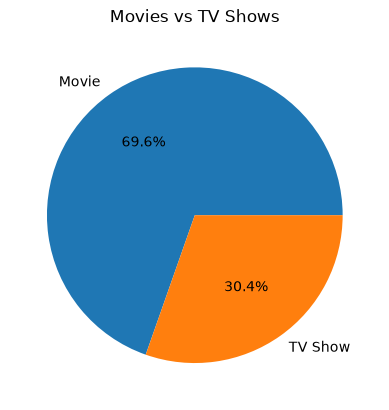

In [27]:
content = netflix['content_type'].value_counts()

plt.pie(content, labels=content.index, autopct='%1.1f%%')
plt.title('Movies vs TV Shows')
plt.show()

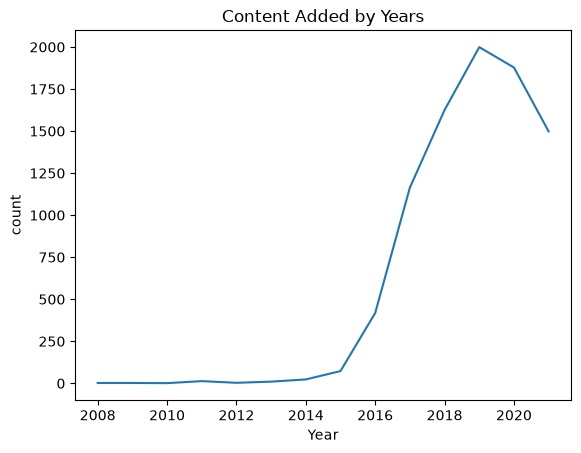

In [28]:
year = netflix['date_added'].dt.year.value_counts().sort_index()

sns.lineplot(x=year.index, y=year.values)
plt.xlabel('Year')
plt.ylabel('count')
plt.title('Content Added by Years')
plt.show()

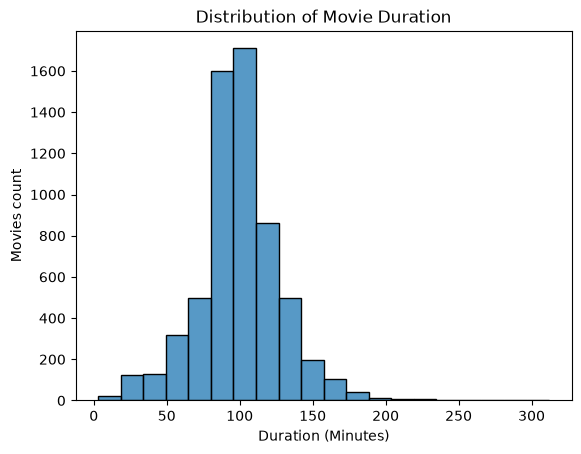

In [29]:
movies = netflix[netflix['content_type'] == 'Movie']

duration = movies['duration'].str.replace(' min', '', regex=False).astype(float)

sns.histplot(duration, bins=20)
plt.xlabel('Duration (Minutes)')
plt.ylabel('Movies count')
plt.title('Distribution of Movie Duration')
plt.show()

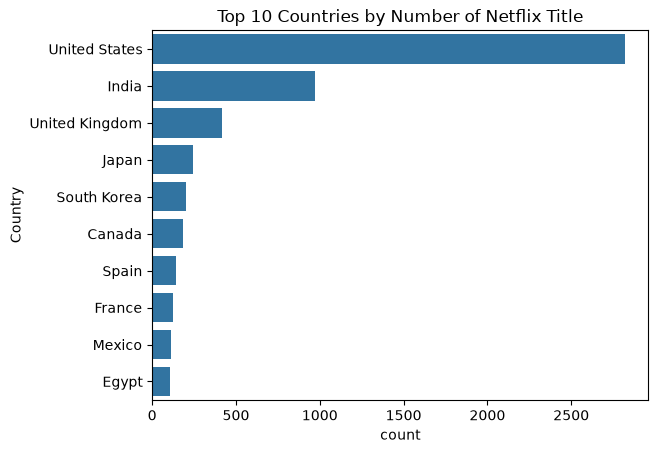

In [30]:
top_countries = (
    netflix.loc[netflix['country'] != 'Unknown', 'country']
    .value_counts()
    .head(10)
)

sns.barplot(x=top_countries.values, y=top_countries.index)
plt.xlabel('count')
plt.ylabel('Country')
plt.title('Top 10 Countries by Number of Netflix Title')
plt.show()

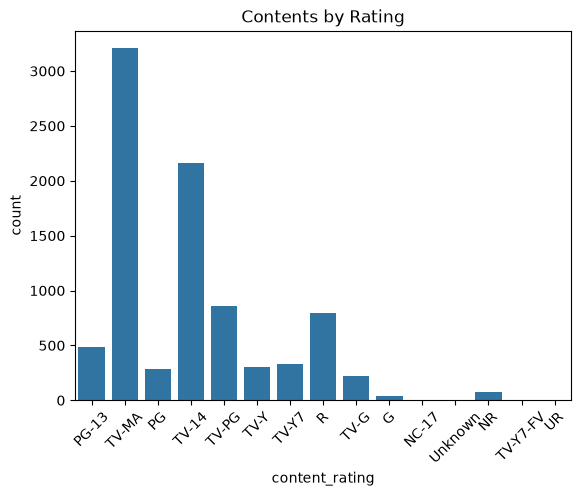

In [31]:
sns.countplot(data=netflix, x='content_rating')
plt.title('Contents by Rating')
plt.xticks(rotation=45)
plt.show()


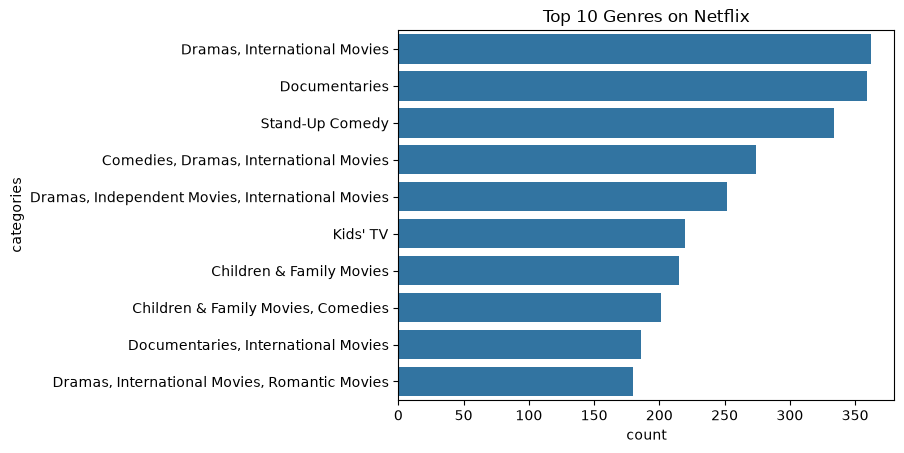

In [33]:
genre = netflix['genre'].value_counts().head(10)

sns.barplot(x=genre.values, y=genre.index)
plt.xlabel('count')
plt.ylabel('categories')
plt.title('Top 10 Genres on Netflix')
plt.show()

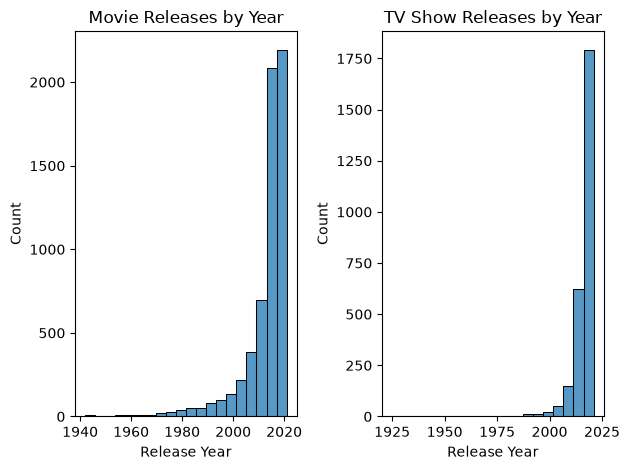

In [34]:
plt.subplot(1, 2, 1)
movie_data = netflix[netflix['content_type'] == 'Movie']

sns.histplot(data=movie_data, x='release_year', bins=20)
plt.xlabel('Release Year')
plt.ylabel('Count')
plt.title('Movie Releases by Year')

plt.subplot(1, 2, 2)
tv_data = netflix[netflix['content_type'] == 'TV Show']

sns.histplot(data=tv_data, x='release_year', bins=20)
plt.xlabel('Release Year')
plt.ylabel('Count')
plt.title('TV Show Releases by Year')

plt.tight_layout()
plt.show()

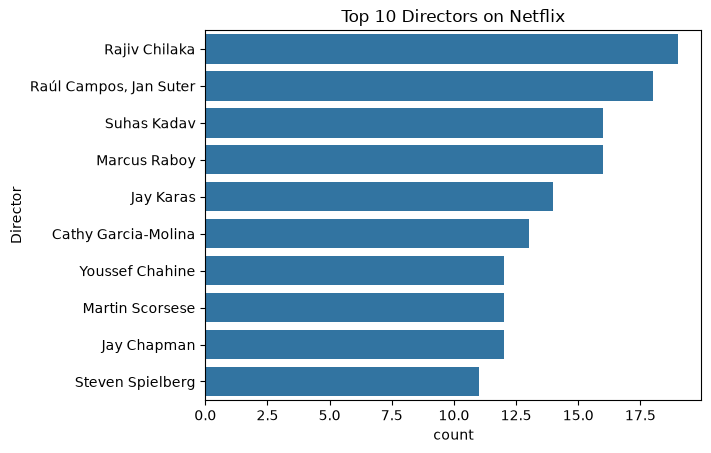

In [35]:
director_data = netflix[netflix['director'] != 'Unknown']

top_directors = director_data['director'].value_counts().head(10)

sns.barplot(x=top_directors.values, y=top_directors.index)

plt.xlabel('count')
plt.ylabel('Director')
plt.title('Top 10 Directors on Netflix')
plt.show()

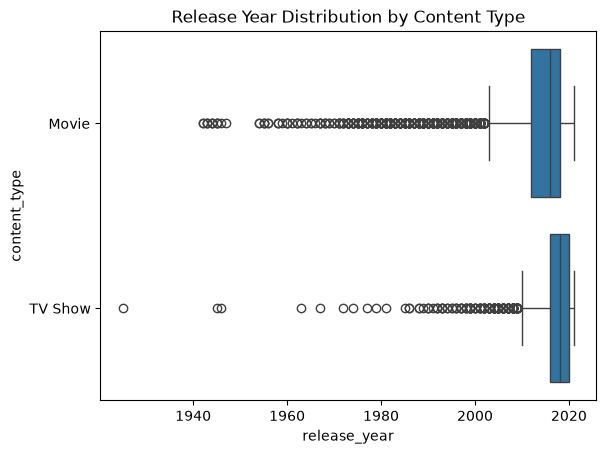

In [36]:
sns.boxplot(data=netflix, y='content_type', x='release_year')
plt.title('Release Year Distribution by Content Type')
plt.show()

## Conclusion

- Movies are more common than TV shows on Netflix.

- Most movies are around 80–120 minutes long.

- The USA has the highest number of titles, followed by India.

- TV-MA is the most common rating.

- Netflix content increased greatly after 2010.

- Drama and International Movies are among the top genres.

- Overall, Netflix has a large and diverse collection of content.